# 02 — Exploratory Data Analysis (EDA)

Notebook này khám phá phân phối sales, xu hướng và mùa vụ, khác biệt giữa cửa hàng/nhóm sản phẩm, promotion, transactions, giá dầu, ngày lễ và zero sales để làm căn cứ cho preprocessing.

**Phạm vi:** chỉ phân tích và trực quan hóa. Không xóa dòng, điền missing, loại outlier, tạo bảng modeling hoặc lag features. Tương quan transactions cùng ngày chỉ dùng cho EDA, không phải feature có thể dùng trực tiếp để dự báo.


## 1. Import, tìm project root và đọc dữ liệu

Notebook đọc độc lập sáu bảng cần cho EDA. Không thay đổi dữ liệu gốc.


In [54]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
print("Pandas:", pd.__version__, "NumPy:", np.__version__, "Seaborn:", sns.__version__)


Pandas: 3.1.1 NumPy: 2.5.4 Seaborn: 0.13.2


In [55]:
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "data" / "raw" / "train.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Không tìm thấy data/raw/train.csv. Mở notebook từ repo hoặc thư mục con.")
DATA_DIR = ROOT / "data" / "raw"
EDA_DIR = ROOT / "reports" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["date"], low_memory=False)
test = pd.read_csv(DATA_DIR / "test.csv", parse_dates=["date"], low_memory=False)
stores = pd.read_csv(DATA_DIR / "stores.csv")
oil = pd.read_csv(DATA_DIR / "oil.csv", parse_dates=["date"])
holidays = pd.read_csv(DATA_DIR / "holidays_events.csv", parse_dates=["date"])
transactions = pd.read_csv(DATA_DIR / "transactions.csv", parse_dates=["date"])
datasets = {"train":train,"test":test,"stores":stores,"oil":oil,"holidays":holidays,"transactions":transactions}
shape_report = pd.DataFrame([{"dataset":n,"rows":len(d),"columns":d.shape[1],"memory_MB":round(d.memory_usage(deep=True).sum()/1024**2,2)} for n,d in datasets.items()])
print("Project root:", ROOT)
display(shape_report)


Project root: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-


,dataset,rows,columns,memory_MB
0,train,3000888,6,168.16
1,test,28512,5,1.38
2,stores,54,5,0.00
3,oil,1218,2,0.02
4,holidays,350,6,0.03
5,transactions,83488,3,1.91


## 2. Sales distribution

Mô tả phạm vi, độ lệch, zero sales và phần đuôi phân phối. Giá trị lớn không mặc định là lỗi.


,sales
count,3.000888e+06
mean,3.577757e+02
std,1.101998e+03
min,0.000000e+00
1%,0.000000e+00
5%,0.000000e+00
25%,0.000000e+00
50%,1.100000e+01
75%,1.958473e+02
90%,8.670000e+02


Skewness: 7.3587578188826415 Kurtosis: 154.56209236964776
Zero rate: 31.30% Negative sales: 0


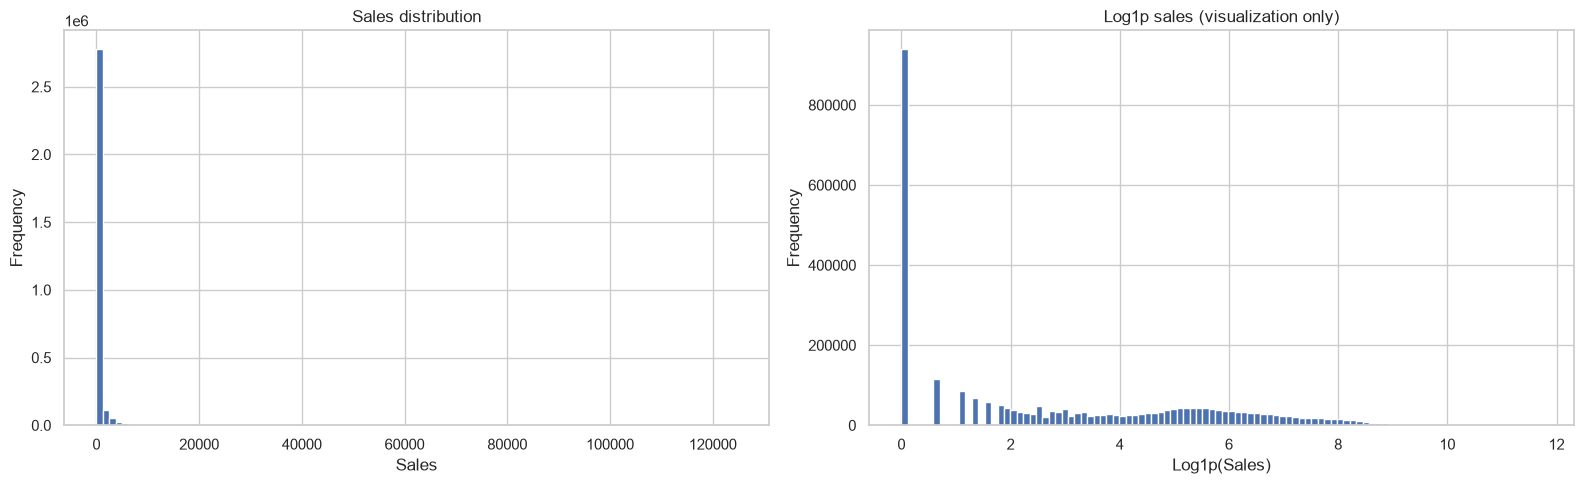

,sales
0.900,867.000000
0.950,1965.000000
0.990,5507.000000
0.995,7448.000000
0.999,12076.225548
1.000,124717.000000


,date,store_nbr,family,sales,onpromotion
2163723,2016-05-02,2,GROCERY I,124717.000,59
2445984,2016-10-07,39,MEATS,89576.360,0
2144154,2016-04-21,20,GROCERY I,87438.516,53
2139699,2016-04-18,45,GROCERY I,76090.000,38
2153031,2016-04-26,2,GROCERY I,63434.000,30
2145045,2016-04-21,45,GROCERY I,53874.000,44
562596,2013-11-12,44,GROCERY I,46271.000,0
1257246,2014-12-08,35,GROCERY I,45361.000,3
1916586,2015-12-14,35,GROCERY I,40351.460,7
2760297,2017-04-02,9,GROCERY I,38422.625,73


In [56]:
sales_summary = train.sales.describe(percentiles=[.01,.05,.25,.50,.75,.90,.95,.99,.999]).to_frame("sales")
display(sales_summary)
print("Skewness:", train.sales.skew(), "Kurtosis:", train.sales.kurt())
print("Zero rate:", f"{train.sales.eq(0).mean():.2%}", "Negative sales:", int(train.sales.lt(0).sum()))
fig, axes = plt.subplots(1, 2, figsize=(16,5))
axes[0].hist(train.sales, bins=100); axes[0].set(title="Sales distribution", xlabel="Sales", ylabel="Frequency")
axes[1].hist(np.log1p(train.sales.clip(lower=0)), bins=100); axes[1].set(title="Log1p sales (visualization only)", xlabel="Log1p(Sales)", ylabel="Frequency")
plt.tight_layout(); plt.show()
sales_quantiles = train.sales.quantile([.90,.95,.99,.995,.999,1.0]).to_frame("sales")
top_sales = train.nlargest(20,"sales")[["date","store_nbr","family","sales","onpromotion"]]
display(sales_quantiles); display(top_sales)


`log1p` ở đây chỉ phục vụ trực quan hóa; không thay đổi `train.sales`. Quan sát độ lệch, tỷ lệ zero, các phân vị cao và đặc điểm của các dòng doanh số lớn.


## 3. Xu hướng theo thời gian và mùa vụ

Tổng hợp theo các ngày thực sự có trong train. Bốn ngày 25/12 bị thiếu sẽ được giữ là khoảng trống, không tự tạo ngày.


,date,total_sales,average_sales
0,2013-01-01,2511.618999,1.409438
1,2013-01-02,496092.417944,278.390807
2,2013-01-03,361461.231124,202.840197
3,2013-01-04,354459.677093,198.911154
4,2013-01-05,477350.121229,267.873244


,date,total_sales,average_sales
1679,2017-08-11,826373.722022,463.733851
1680,2017-08-12,792630.535079,444.798280
1681,2017-08-13,865639.677471,485.768618
1682,2017-08-14,760922.406081,427.004717
1683,2017-08-15,762661.935939,427.980884


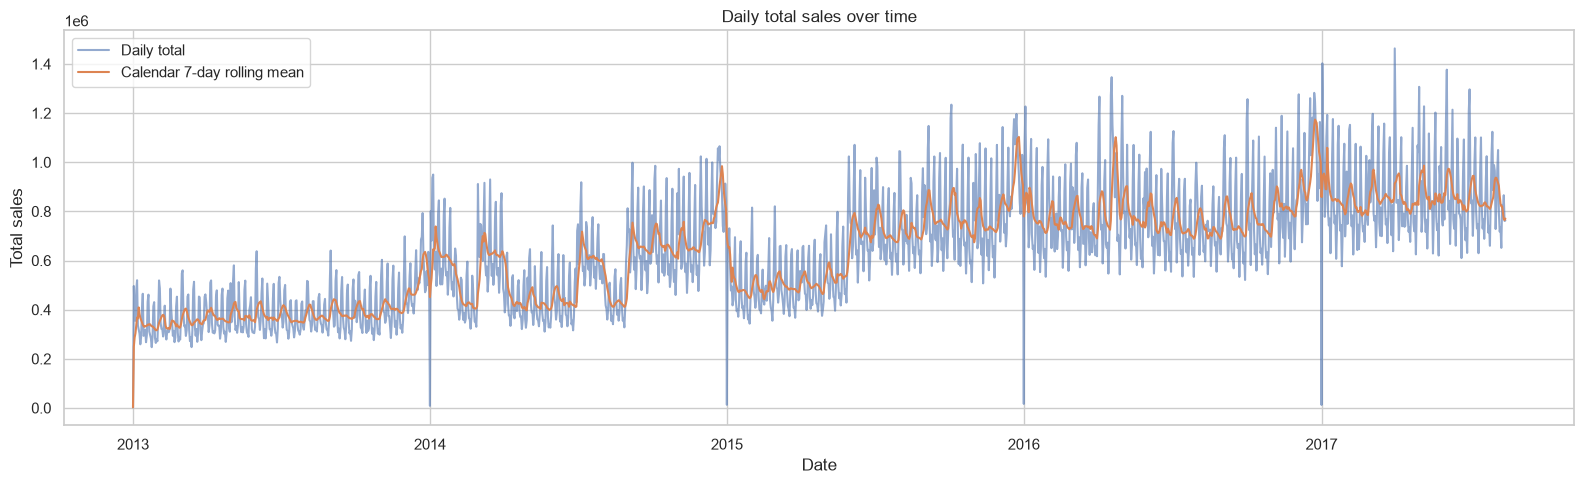

,mean,median,std
Monday,617542.713052,651800.509461,202901.445868
Tuesday,569926.087922,602440.102499,199672.002474
Wednesday,593244.553472,632951.683756,206976.013112
Thursday,505269.201115,531402.203129,168677.994700
Friday,579574.361085,616645.013015,191907.914811
Saturday,772205.593943,816064.644983,221747.538455
Sunday,825218.121579,862268.400242,257472.920530


,mean,median,std
month,,,
1,609304.208495,576515.536988,268236.797184
2,571895.244225,530128.059914,219403.982491
3,627280.562239,622695.836995,217025.087837
4,604454.117050,522357.650030,261373.165502
5,609026.690473,573412.210160,241142.624990
6,630111.355279,637526.407289,227399.443294
7,666858.456059,654821.051531,214114.781500
8,600520.696680,625898.205888,200249.198190
9,645613.999338,641160.480437,208425.894711


month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2013,333149.185062,344962.849194,368661.194758,366448.824600,374119.484098,389644.802075,363141.955086,378638.352241,393097.774396,379858.721307,411885.309766,526770.571599
2014,610052.925852,429941.165499,656954.323112,428708.368572,431605.976168,443998.605767,626512.614317,447908.916744,667413.870460,657938.752070,684387.840121,811348.478794
2015,480545.872813,490799.851728,503180.887689,498502.272359,571947.362720,720512.011708,716439.323830,740763.685203,774696.082597,770266.698857,760165.112274,908132.722459
2016,773477.576949,756807.200035,746186.480123,865434.170065,799336.524523,740307.286013,756860.401068,724271.429610,747248.269900,775173.865042,821421.339913,988009.585980
2017,849295.481797,830361.156248,861419.925512,863176.949652,868124.104858,856094.070833,871337.985995,828888.196052,NaN,NaN,NaN,NaN


month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2013,86.360315,89.422703,95.565886,94.992386,96.980807,101.005344,94.135166,98.152206,101.900438,98.468555,106.770621,136.551655
2014,106.007907,74.710179,114.157887,74.495958,74.999470,77.152918,108.868081,77.832406,115.975426,114.328950,118.924965,140.986709
2015,72.616500,74.166004,76.036934,75.329937,86.428410,108.878389,108.262955,111.938670,117.066280,116.396945,114.870469,137.230228
2016,97.805263,95.697315,94.354338,109.433058,101.075094,93.610922,95.704042,91.583208,94.488600,98.019757,103.867691,124.932565
2017,99.265258,97.052223,100.682357,100.887718,101.465939,100.059874,101.841576,96.880064,NaN,NaN,NaN,NaN


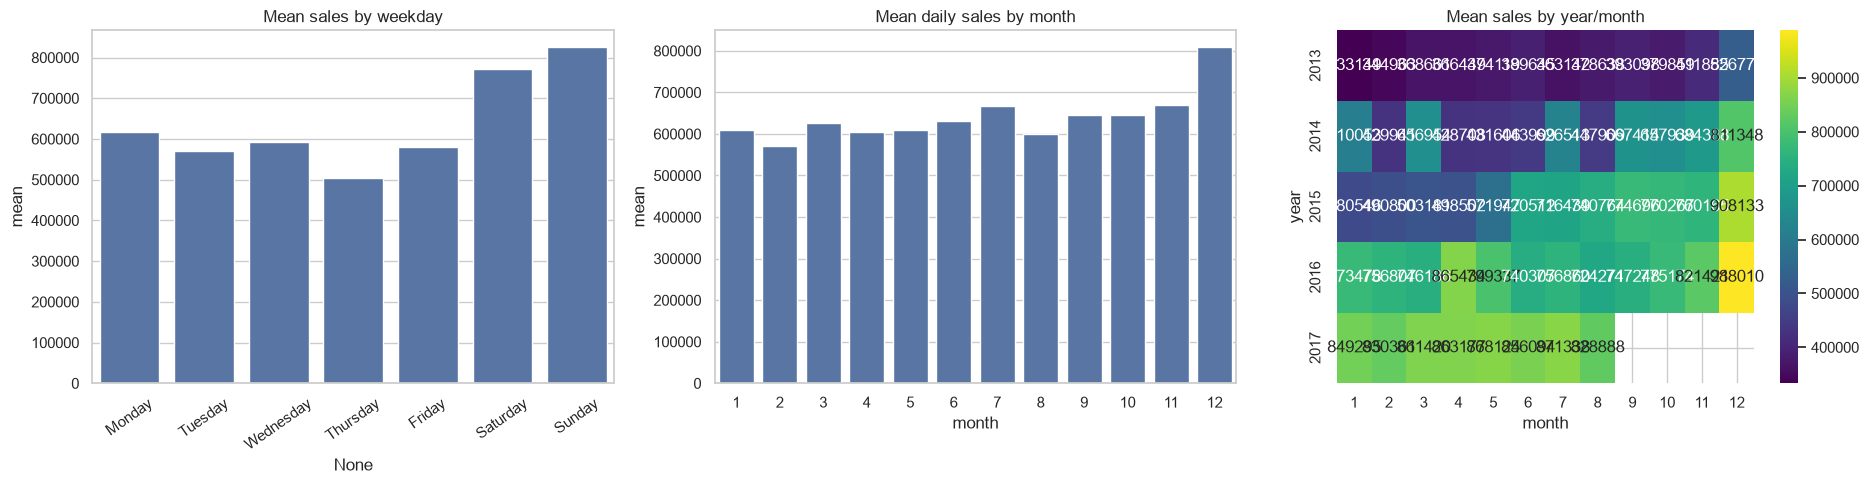

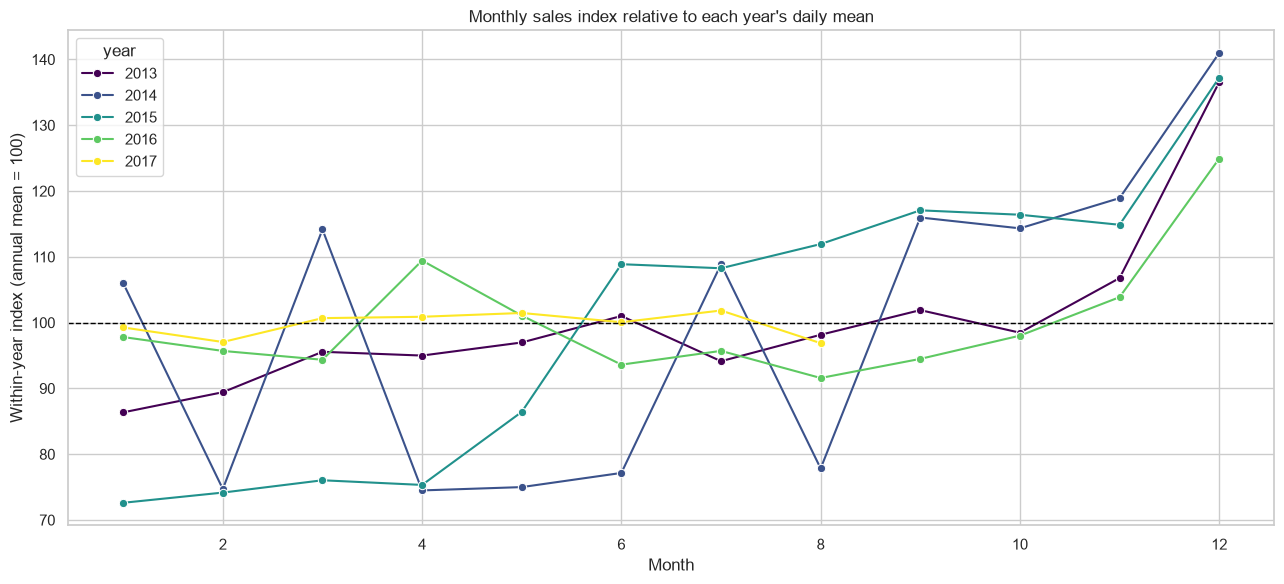

In [57]:
daily_sales = train.groupby("date").sales.agg(total_sales="sum", average_sales="mean").reset_index().sort_values("date")
display(daily_sales.head()); display(daily_sales.tail())
fig, ax = plt.subplots(figsize=(16,5))
ax.plot(daily_sales.date,daily_sales.total_sales,alpha=.6,label="Daily total")
rolling_7d = daily_sales.set_index("date").total_sales.rolling("7D",min_periods=1).mean()
ax.plot(daily_sales.date,rolling_7d.values,label="Calendar 7-day rolling mean")
ax.set(title="Daily total sales over time",xlabel="Date",ylabel="Total sales"); ax.legend(); plt.tight_layout(); plt.show()
weekday_order=["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekday_summary=(daily_sales.assign(dayofweek=daily_sales.date.dt.day_of_week).groupby("dayofweek").total_sales.agg(["mean","median","std"]).reindex(range(7)))
weekday_summary.index=weekday_order
daily_sales["month"]=daily_sales.date.dt.month; daily_sales["year"]=daily_sales.date.dt.year
month_summary=daily_sales.groupby("month").total_sales.agg(mean="mean",median="median",std="std")
year_month_sales=daily_sales.pivot_table(index="year",columns="month",values="total_sales",aggfunc="mean")
monthly_by_year=daily_sales.groupby(["year","month"]).total_sales.mean().rename("mean_daily_sales").reset_index()
annual_baseline=daily_sales.groupby("year").total_sales.mean().rename("annual_mean_daily_sales").reset_index()
monthly_by_year=monthly_by_year.merge(annual_baseline,on="year",validate="many_to_one")
monthly_by_year["within_year_month_index"]=100*monthly_by_year.mean_daily_sales/monthly_by_year.annual_mean_daily_sales
normalized_year_month=monthly_by_year.pivot(index="year",columns="month",values="within_year_month_index")
display(weekday_summary); display(month_summary); display(year_month_sales); display(normalized_year_month)
fig, axes=plt.subplots(1,3,figsize=(19,5))
sns.barplot(x=weekday_summary.index,y=weekday_summary["mean"],ax=axes[0]); axes[0].tick_params(axis="x",rotation=35); axes[0].set_title("Mean sales by weekday")
sns.barplot(x=month_summary.index,y=month_summary["mean"],ax=axes[1]); axes[1].set_title("Mean daily sales by month")
sns.heatmap(year_month_sales,annot=True,fmt=".0f",ax=axes[2],cmap="viridis"); axes[2].set_title("Mean sales by year/month")
plt.tight_layout(); plt.show()
plt.figure(figsize=(13,6))
sns.lineplot(data=monthly_by_year,x="month",y="within_year_month_index",hue="year",marker="o",palette="viridis")
plt.axhline(100,color="black",linewidth=1,linestyle="--")
plt.title("Monthly sales index relative to each year's daily mean")
plt.xlabel("Month"); plt.ylabel("Within-year index (annual mean = 100)")
plt.tight_layout(); plt.show()


So sánh trung bình gộp theo tháng có thể bị ảnh hưởng bởi xu hướng tăng trưởng qua năm. Biểu đồ `within_year_month_index` chuẩn hóa mỗi tháng theo trung bình ngày của chính năm đó (100 = trung bình năm), giúp quan sát pattern tháng sau khi tách khác biệt quy mô giữa các năm. Bốn ngày 25/12 vẫn vắng khỏi dữ liệu, không được tạo thêm.


## 4. Store, Family và 1.782 Store-Family series

Các thống kê zero rate chỉ dùng để nhận diện series cần xem xét, không kết luận structural zero.


,total_sales,mean_daily_sales,median_daily_sales,zero_rate,record_count
family,,,,,
GROCERY I,3.434627e+08,3776.972100,3185.0000,0.080628,90936
BEVERAGES,2.169545e+08,2385.793151,1784.0000,0.080617,90936
PRODUCE,1.227047e+08,1349.352123,398.2905,0.283551,90936
CLEANING,9.752129e+07,1072.416744,938.0000,0.080617,90936
DAIRY,6.448771e+07,709.154889,520.0000,0.080617,90936
BREAD/BAKERY,4.213395e+07,463.336254,401.0000,0.080606,90936
POULTRY,3.187600e+07,350.532292,205.7430,0.080760,90936
MEATS,3.108647e+07,341.849965,224.9365,0.080617,90936
PERSONAL CARE,2.459205e+07,270.432513,222.0000,0.080650,90936


,total_sales,mean_daily_sales,median_daily_sales,zero_rate,record_count
store_nbr,,,,,
44,6.208755e+07,1117.245254,75.0000,0.179479,55572
45,5.449801e+07,980.673908,62.0000,0.193587,55572
47,5.094831e+07,916.798209,51.0000,0.189538,55572
3,5.048191e+07,908.405495,64.0000,0.181404,55572
49,4.342010e+07,781.330450,48.0000,0.193479,55572
46,4.189606e+07,753.905962,36.0000,0.193209,55572
48,3.593313e+07,646.604950,30.0000,0.213219,55572
51,3.291149e+07,592.231511,27.0000,0.201216,55572
8,3.049429e+07,548.734739,39.0000,0.199309,55572


,store_nbr,family,total_sales,mean_daily_sales,median_daily_sales,zero_rate,positive_days,n_observations
0,1,AUTOMOTIVE,5475.0,3.251188,3.0,0.131235,1463,1684
1,1,BABY CARE,0.0,0.000000,0.0,1.000000,0,1684
2,1,BEAUTY,4056.0,2.408551,2.0,0.150831,1430,1684
3,1,BEVERAGES,2673769.0,1587.748812,1674.0,0.003563,1678,1684
4,1,BOOKS,211.0,0.125297,0.0,0.924584,127,1684


,store_nbr,family,total_sales,mean_daily_sales,median_daily_sales,zero_rate,positive_days,n_observations
1,1,BABY CARE,0.0,0.0,0.0,1.0,0,1684
268,9,BOOKS,0.0,0.0,0.0,1.0,0,1684
301,10,BOOKS,0.0,0.0,0.0,1.0,0,1684
334,11,BOOKS,0.0,0.0,0.0,1.0,0,1684
367,12,BOOKS,0.0,0.0,0.0,1.0,0,1684
397,13,BABY CARE,0.0,0.0,0.0,1.0,0,1684
400,13,BOOKS,0.0,0.0,0.0,1.0,0,1684
433,14,BOOKS,0.0,0.0,0.0,1.0,0,1684
449,14,LAWN AND GARDEN,0.0,0.0,0.0,1.0,0,1684
466,15,BOOKS,0.0,0.0,0.0,1.0,0,1684


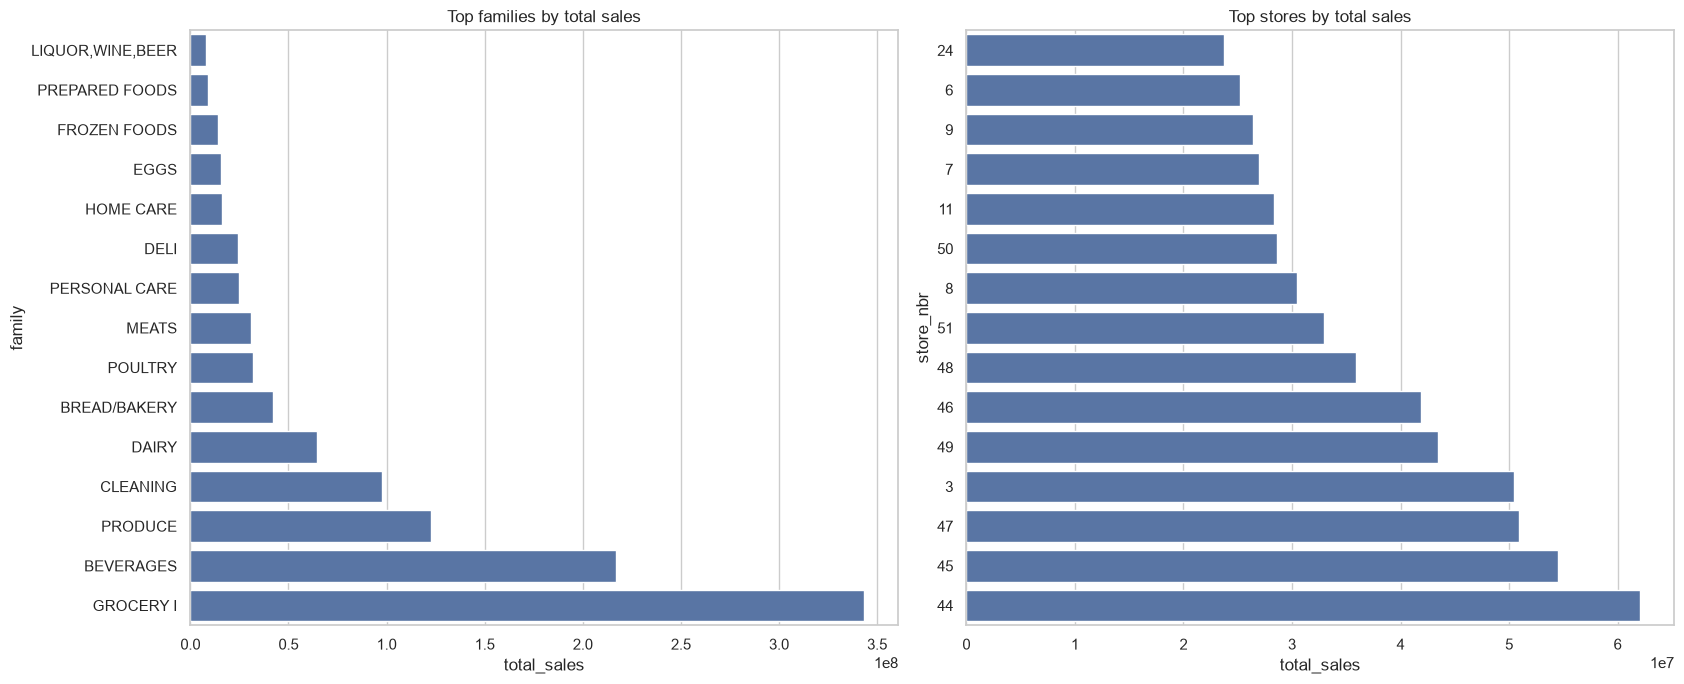

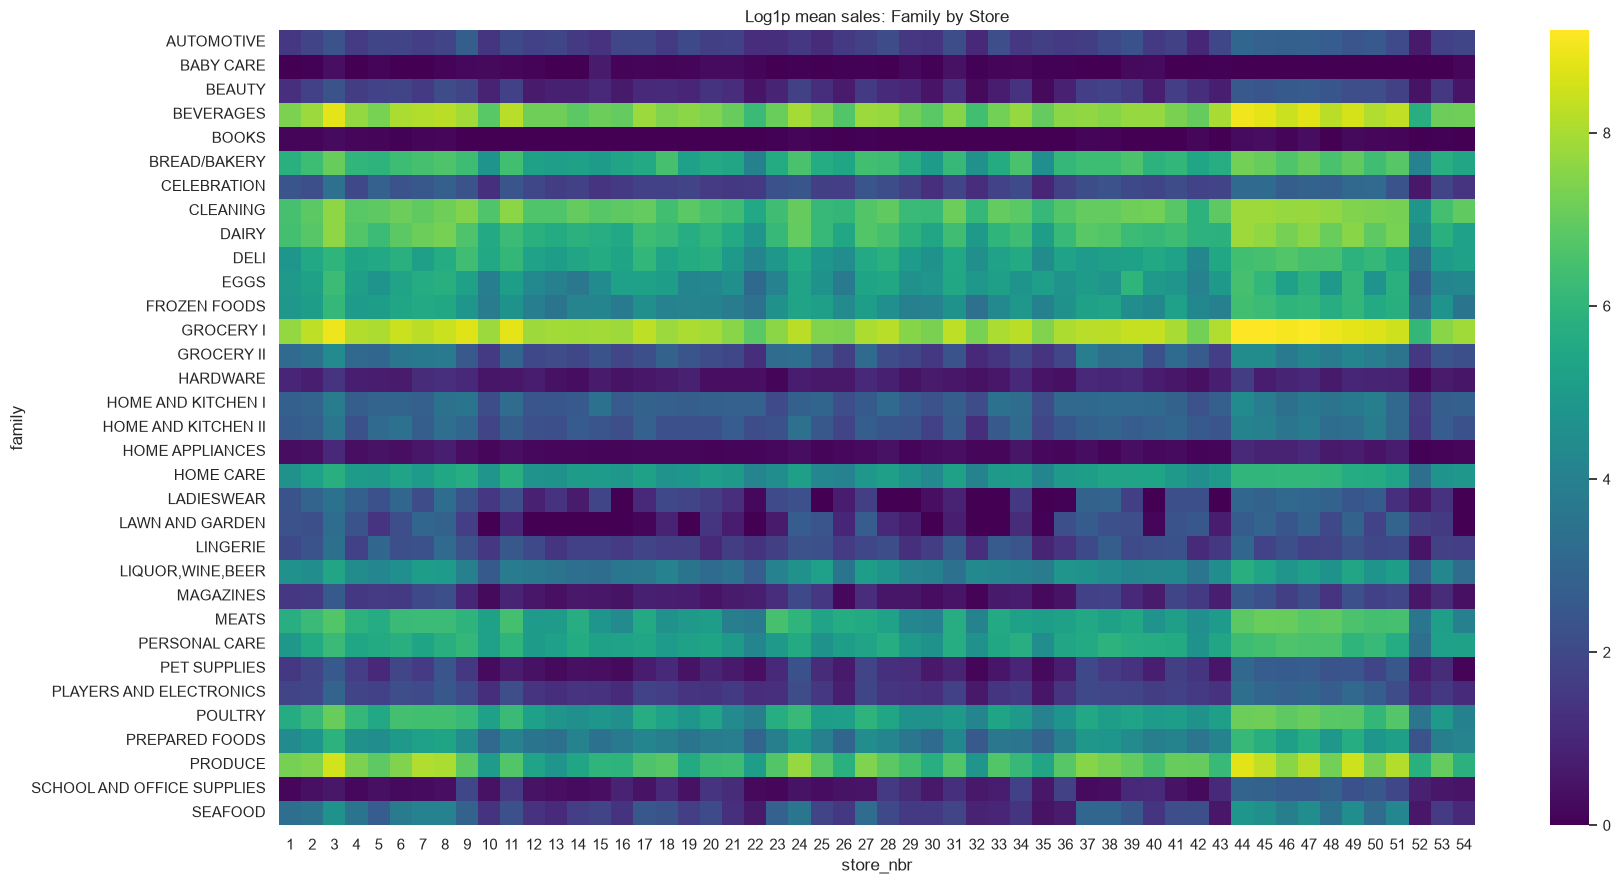

In [58]:
family_summary=train.groupby("family").sales.agg(total_sales="sum",mean_daily_sales="mean",median_daily_sales="median",zero_rate=lambda x:x.eq(0).mean(),record_count="size").sort_values("total_sales",ascending=False)
store_summary=train.groupby("store_nbr").sales.agg(total_sales="sum",mean_daily_sales="mean",median_daily_sales="median",zero_rate=lambda x:x.eq(0).mean(),record_count="size").sort_values("total_sales",ascending=False)
series_summary=train.groupby(["store_nbr","family"]).sales.agg(total_sales="sum",mean_daily_sales="mean",median_daily_sales="median",zero_rate=lambda x:x.eq(0).mean(),positive_days=lambda x:x.gt(0).sum(),n_observations="size").reset_index()
display(family_summary); display(store_summary); display(series_summary.head())
high_zero_series=series_summary.sort_values(["zero_rate","mean_daily_sales"],ascending=[False,True]).head(20)
display(high_zero_series)
fig,axes=plt.subplots(1,2,figsize=(17,7))
sns.barplot(x=family_summary.head(15).sort_values("total_sales").total_sales,y=family_summary.head(15).sort_values("total_sales").index,ax=axes[0]); axes[0].set_title("Top families by total sales")
sns.barplot(x=store_summary.head(15).sort_values("total_sales").total_sales,y=store_summary.head(15).sort_values("total_sales").index.astype(str),ax=axes[1]); axes[1].set_title("Top stores by total sales")
plt.tight_layout(); plt.show()
family_store_matrix=train.pivot_table(index="family",columns="store_nbr",values="sales",aggfunc="mean")
plt.figure(figsize=(18,9)); sns.heatmap(np.log1p(family_store_matrix),cmap="viridis"); plt.title("Log1p mean sales: Family by Store"); plt.tight_layout(); plt.show()


## 5. Promotion

`onpromotion` là số sản phẩm khuyến mãi, không phải cờ 0/1. Liên hệ sales-promotion dưới đây chỉ mang tính mô tả, không chứng minh promotion gây ra doanh số cao hơn.


,onpromotion
count,3.000888e+06
mean,2.602770e+00
std,1.221888e+01
min,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
90%,4.000000e+00
95%,1.300000e+01
99%,5.500000e+01
max,7.410000e+02


Records with promotion: 611329 Promotion rate: 20.37%


,record_count,mean_sales,median_sales,zero_rate
onpromotion,,,,
0,2389559,158.246681,3.0000,0.393007
1,174551,467.556532,145.3480,0.000034
2-5,181447,816.214649,295.0000,0.000028
6-10,82973,1133.186482,396.6350,0.000012
11-20,67498,1403.325230,623.0000,0.000030
21-50,68589,2167.008534,1395.6140,0.000000
51-100,27355,3300.882681,2723.9320,0.000073
>100,8916,4275.335174,3174.6805,0.000112


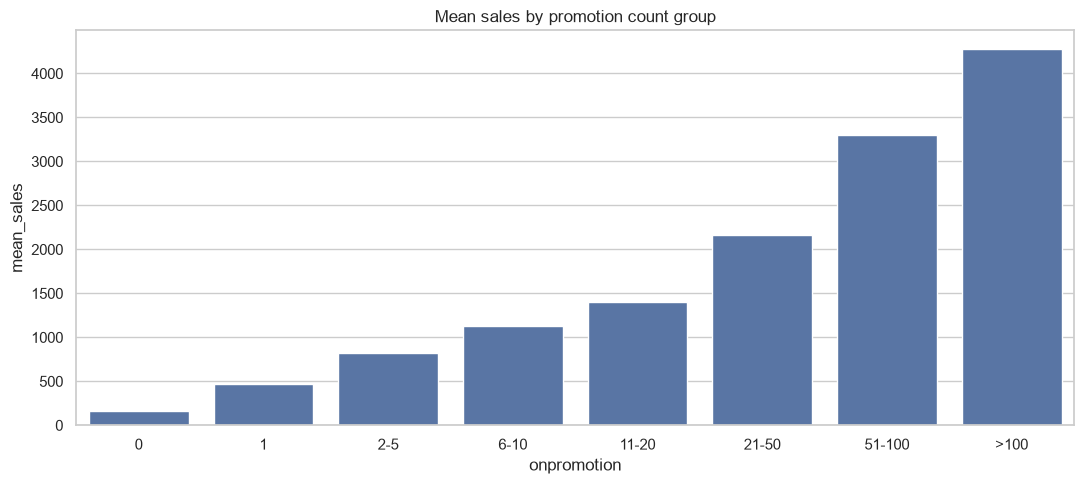

,test_onpromotion
count,28512.000000
mean,6.965383
std,20.683952
min,0.000000
25%,0.000000
50%,0.000000
75%,6.000000
max,646.000000


In [59]:
promotion_summary=train.onpromotion.describe(percentiles=[.5,.75,.90,.95,.99]).to_frame("onpromotion")
display(promotion_summary)
print("Records with promotion:",int(train.onpromotion.gt(0).sum()),"Promotion rate:",f"{train.onpromotion.gt(0).mean():.2%}")
promo_bins=[-1,0,1,5,10,20,50,100,np.inf]; promo_labels=["0","1","2-5","6-10","11-20","21-50","51-100",">100"]
promo_group=pd.cut(train.onpromotion,bins=promo_bins,labels=promo_labels)
promo_sales_summary=train.groupby(promo_group,observed=False).sales.agg(record_count="size",mean_sales="mean",median_sales="median",zero_rate=lambda x:x.eq(0).mean())
display(promo_sales_summary)
plt.figure(figsize=(11,5)); sns.barplot(x=promo_sales_summary.index.astype(str),y=promo_sales_summary.mean_sales); plt.title("Mean sales by promotion count group"); plt.tight_layout(); plt.show()
display(test.onpromotion.describe().to_frame("test_onpromotion"))


## 6. Transactions

Tổng hợp sales về Store-Date rồi nối giao dịch theo đúng hai khóa. Đây là tương quan đồng thời để khám phá dữ liệu; giao dịch tương lai không có trong test và không được dùng trực tiếp làm feature dự báo sales.


Rows before/after merge: 90936 90936 Missing transactions: 7448


,total_sales,transactions
total_sales,1.000000,0.817464
transactions,0.817464,1.000000


Valid Store-Date observations: 83488


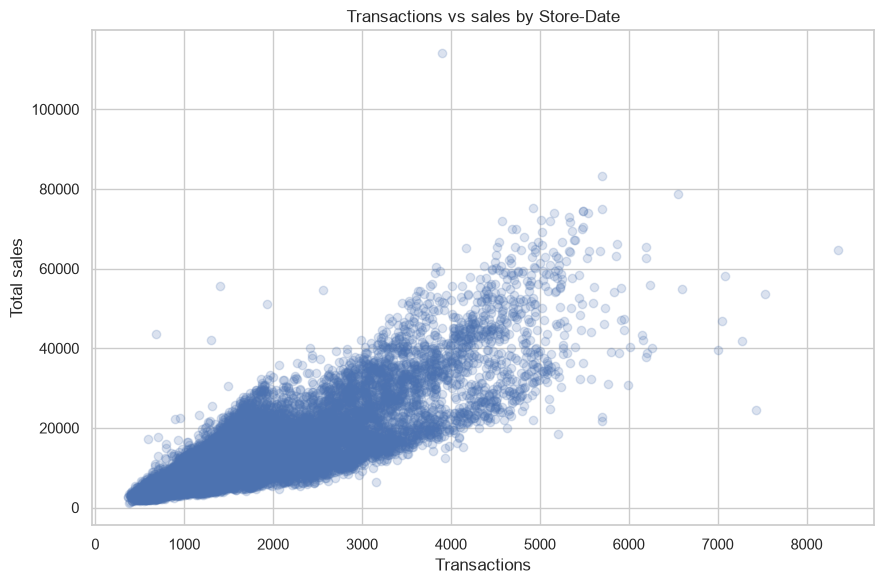

In [60]:
store_day_sales=train.groupby(["date","store_nbr"]).sales.sum().rename("total_sales").reset_index()
store_day_analysis=store_day_sales.merge(transactions,on=["date","store_nbr"],how="left",validate="one_to_one")
assert len(store_day_analysis)==len(store_day_sales)
print("Rows before/after merge:",len(store_day_sales),len(store_day_analysis),"Missing transactions:",int(store_day_analysis.transactions.isna().sum()))
valid_transaction_data=store_day_analysis.dropna(subset=["transactions","total_sales"])
transaction_corr=valid_transaction_data[["total_sales","transactions"]].corr(method="spearman")
display(transaction_corr); print("Valid Store-Date observations:",len(valid_transaction_data))
plot_data=valid_transaction_data.sample(n=min(20000,len(valid_transaction_data)),random_state=42)
plt.figure(figsize=(9,6)); plt.scatter(plot_data.transactions,plot_data.total_sales,alpha=.2); plt.title("Transactions vs sales by Store-Date"); plt.xlabel("Transactions"); plt.ylabel("Total sales"); plt.tight_layout(); plt.show()


## 7. Oil

Báo cáo missing và quan sát mối liên hệ với sales; chưa điền missing. Giá dầu và doanh số cùng thay đổi theo thời gian nên tương quan không chứng minh quan hệ nhân quả.


,dcoilwtico
count,1175.000000
mean,67.714366
std,25.630476
min,26.190000
25%,46.405000
50%,53.190000
75%,95.660000
max,110.620000


Explicit missing oil prices: 43 Oil source rows: 1218


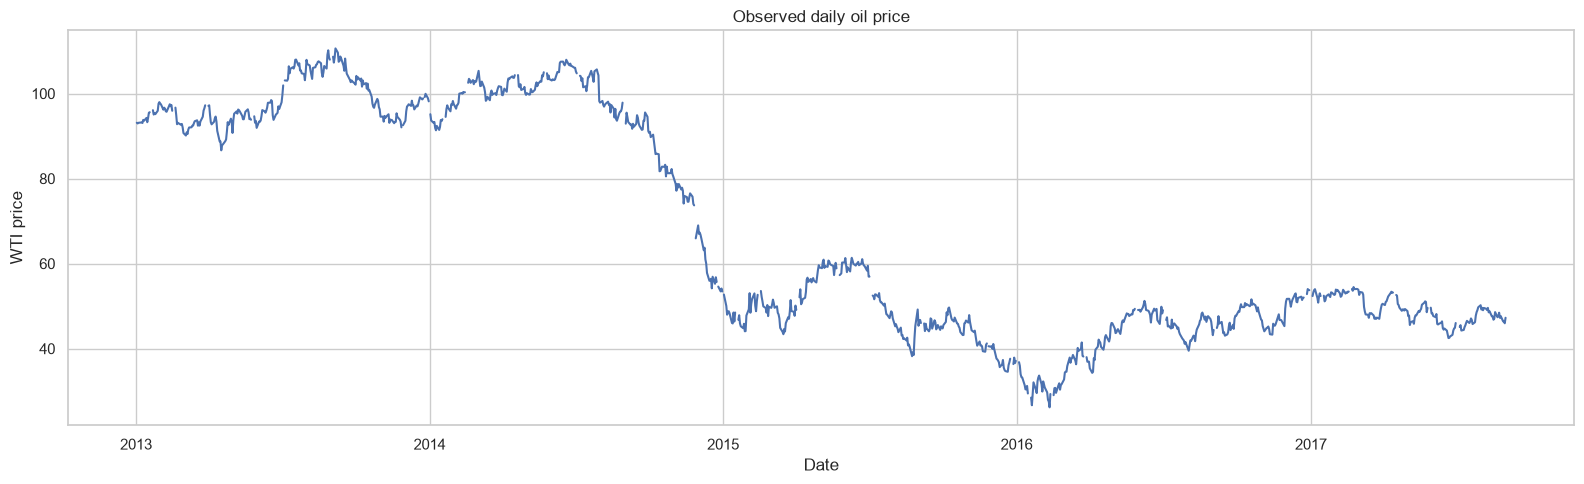

Train dates with missing oil after left join: 521


,total_sales,dcoilwtico
total_sales,1.000000,-0.660286
dcoilwtico,-0.660286,1.000000


Valid daily observations: 1163


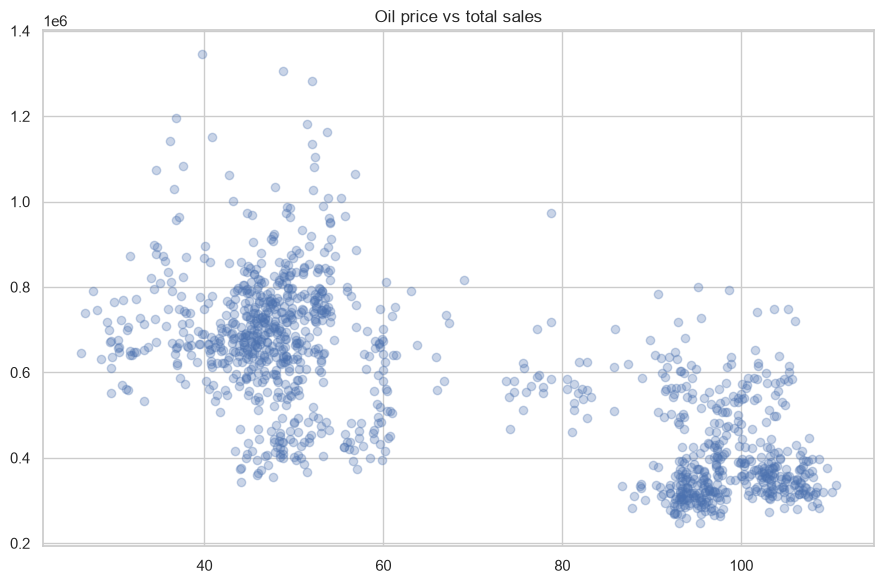

In [61]:
oil_summary=oil.dcoilwtico.describe(percentiles=[.25,.50,.75]).to_frame("dcoilwtico")
display(oil_summary); print("Explicit missing oil prices:",int(oil.dcoilwtico.isna().sum()),"Oil source rows:",len(oil))
plt.figure(figsize=(16,5)); plt.plot(oil.date,oil.dcoilwtico); plt.title("Observed daily oil price"); plt.xlabel("Date"); plt.ylabel("WTI price"); plt.tight_layout(); plt.show()
daily_sales_oil=daily_sales[["date","total_sales"]].merge(oil[["date","dcoilwtico"]],on="date",how="left",validate="one_to_one")
print("Train dates with missing oil after left join:",int(daily_sales_oil.dcoilwtico.isna().sum()))
valid_oil_data=daily_sales_oil.dropna(subset=["total_sales","dcoilwtico"])
oil_corr=valid_oil_data[["total_sales","dcoilwtico"]].corr(method="spearman")
display(oil_corr); print("Valid daily observations:",len(valid_oil_data))
plt.figure(figsize=(9,6)); plt.scatter(valid_oil_data.dcoilwtico,valid_oil_data.total_sales,alpha=.3); plt.title("Oil price vs total sales"); plt.tight_layout(); plt.show()


## 8. Holidays và events

Ngoài số lượng sự kiện, phần này so sánh doanh số Store-Date theo phạm vi và loại event. Ngày lễ có `transferred=True` được xem là ngày ban đầu bị chuyển: không tính vào ngày nghỉ hoạt động. Ngày tổ chức thực tế được nhận diện bằng `type="Transfer"`. Event và Work Day được phân tích riêng. Đây là so sánh mô tả, không phải kết luận nhân quả.


In [62]:
holiday_type_summary=holidays.type.value_counts(dropna=False).to_frame("event_count")
holiday_locale_summary=holidays.locale.value_counts(dropna=False).to_frame("event_count")
transferred_summary=holidays.transferred.value_counts(dropna=False).to_frame("event_count")
display(holiday_type_summary); display(holiday_locale_summary); display(transferred_summary)
holiday_day_summary=holidays.groupby("date").agg(event_count=("description","size"),event_types=("type",lambda x:", ".join(sorted(set(x.dropna().astype(str))))),locales=("locale",lambda x:", ".join(sorted(set(x.dropna().astype(str)))))).reset_index()
display(holiday_day_summary.head(20)); print("Dates with multiple event records:",int(holiday_day_summary.event_count.gt(1).sum()))

# Match events to stores by geographic scope, then compare at Store-Date level.
store_lookup=stores[["store_nbr","city","state"]].copy()
national=holidays.loc[holidays.locale.eq("National")].merge(store_lookup,how="cross")
regional=holidays.loc[holidays.locale.eq("Regional")].merge(store_lookup,left_on="locale_name",right_on="state",how="inner",validate="many_to_many")
local=holidays.loc[holidays.locale.eq("Local")].merge(store_lookup,left_on="locale_name",right_on="city",how="inner",validate="many_to_many")
holiday_matches=pd.concat([national,regional,local],ignore_index=True)
holiday_matches["is_transferred_original"]=holiday_matches.transferred.fillna(False).astype(bool)
holiday_matches["is_transfer_date"]=holiday_matches.type.eq("Transfer")
holiday_matches["is_active_holiday"]=(~holiday_matches.is_transferred_original & holiday_matches.type.isin(["Holiday","Additional","Bridge","Transfer"]))
holiday_matches["is_event"]=holiday_matches.type.eq("Event") & ~holiday_matches.is_transferred_original
holiday_matches["is_work_day"]=holiday_matches.type.eq("Work Day")
holiday_matches["transferred_original_count"]=holiday_matches.is_transferred_original.astype("int8")
holiday_matches["active_holiday_count"]=holiday_matches.is_active_holiday.astype("int8")
holiday_matches["transfer_date_count"]=holiday_matches.is_transfer_date.astype("int8")
holiday_matches["event_count"]=holiday_matches.is_event.astype("int8")
holiday_matches["work_day_count"]=holiday_matches.is_work_day.astype("int8")
for loc in ["National","Regional","Local"]:
    slug=loc.lower()
    holiday_matches[f"active_locale_{slug}_count"]=(holiday_matches.is_active_holiday & holiday_matches.locale.eq(loc)).astype("int8")
for event_type in ["Holiday","Additional","Bridge","Transfer"]:
    slug=event_type.lower()
    holiday_matches[f"active_type_{slug}_count"]=(holiday_matches.is_active_holiday & holiday_matches.type.eq(event_type)).astype("int8")
holiday_store_eda=holiday_matches.groupby(["date","store_nbr"],as_index=False).agg(
    matched_event_count=("description","size"),transferred_original_count=("transferred_original_count","sum"),
    active_holiday_count=("active_holiday_count","sum"),transfer_date_count=("transfer_date_count","sum"),
    event_count=("event_count","sum"),work_day_count=("work_day_count","sum"),
    active_holiday_types=("type",lambda x:" | ".join(sorted(set(holiday_matches.loc[x.index].loc[holiday_matches.loc[x.index,"is_active_holiday"],"type"].dropna().astype(str))))),
    **{col:(col,"sum") for col in holiday_matches.columns if col.endswith("_count") and col not in {"transferred_original_count","active_holiday_count","transfer_date_count","event_count","work_day_count"}}
)
store_day_holiday=store_day_sales.merge(holiday_store_eda,on=["date","store_nbr"],how="left",validate="one_to_one")
holiday_count_cols=[c for c in store_day_holiday.columns if c.endswith("_count")]
store_day_holiday[holiday_count_cols]=store_day_holiday[holiday_count_cols].fillna(0)
store_day_holiday["active_holiday_types"]=store_day_holiday.active_holiday_types.fillna("")
flag_specs={
 "Any active holiday":"active_holiday_count",
 "Holiday":"active_type_holiday_count",
 "Additional":"active_type_additional_count",
 "Bridge":"active_type_bridge_count",
 "Transfer date":"transfer_date_count",
 "Event":"event_count",
 "Work Day":"work_day_count",
 "National active holiday":"active_locale_national_count",
 "Regional active holiday":"active_locale_regional_count",
 "Local active holiday":"active_locale_local_count"}
holiday_comparison=[]
for label,column in flag_specs.items():
    flag=store_day_holiday[column].gt(0)
    for group_name,mask in [("event_day",flag),("not_in_category",~flag)]:
        values=store_day_holiday.loc[mask,"total_sales"]
        holiday_comparison.append({"category":label,"group":group_name,"store_day_count":int(mask.sum()),
            "mean_sales":values.mean(),"median_sales":values.median(),"zero_rate":values.eq(0).mean()})
holiday_sales_comparison=pd.DataFrame(holiday_comparison)
display(holiday_sales_comparison)


,event_count
type,
Holiday,221
Event,56
Additional,51
Transfer,12
Bridge,5
Work Day,5


,event_count
locale,
National,174
Local,152
Regional,24


,event_count
transferred,
False,338
True,12


,date,event_count,event_types,locales
0,2012-03-02,1,Holiday,Local
1,2012-04-01,1,Holiday,Regional
2,2012-04-12,1,Holiday,Local
3,2012-04-14,1,Holiday,Local
4,2012-04-21,1,Holiday,Local
5,2012-05-12,1,Holiday,Local
6,2012-06-23,1,Holiday,Local
7,2012-06-25,3,Holiday,"Local, Regional"
8,2012-07-03,2,Holiday,Local
9,2012-07-23,1,Holiday,Local


Dates with multiple event records: 31


,category,group,store_day_count,mean_sales,median_sales,zero_rate
0,Any active holiday,event_day,4598,13974.505853,10788.213510,0.117225
1,Any active holiday,not_in_category,86338,11691.146127,9266.078000,0.078656
2,Holiday,event_day,2435,11518.318658,8455.291000,0.163860
3,Holiday,not_in_category,88501,11814.531432,9348.221000,0.078315
4,Additional,event_day,1678,17144.959221,14526.011014,0.069130
5,Additional,not_in_category,89258,11706.241576,9258.308000,0.080822
6,Bridge,event_day,162,14742.778181,11650.245000,0.086420
7,Bridge,not_in_category,90774,11801.359664,9319.344000,0.080596
8,Transfer date,event_day,389,15524.235461,12007.526000,0.041131
9,Transfer date,not_in_category,90547,11790.628343,9313.399000,0.080776


## 9. Zero sales

Xem zero rate theo Family, Store và series; quan sát chuỗi có tỷ lệ zero cao nhất theo thời gian. Không tự động xóa các series này.


,zero_count,zero_rate
family,,
BOOKS,88167,0.969550
BABY CARE,85599,0.941310
SCHOOL AND OFFICE SUPPLIES,67368,0.740829
HOME APPLIANCES,66854,0.735176
LADIESWEAR,54422,0.598465
MAGAZINES,51414,0.565387
PET SUPPLIES,49665,0.546153
HARDWARE,43524,0.478622
LAWN AND GARDEN,42544,0.467846


,zero_count,zero_rate
store_nbr,,
52,51982,0.935399
22,38094,0.685489
42,34575,0.622166
21,34066,0.613007
29,31797,0.572177
20,30271,0.544717
53,24028,0.432376
32,21995,0.395793
35,21738,0.391168


,store_nbr,family,total_sales,mean_daily_sales,median_daily_sales,zero_rate,positive_days,n_observations
1753,54,BOOKS,0.0,0.0,0.0,1.0,0,1684
1618,50,BABY CARE,0.0,0.0,0.0,1.0,0,1684
1585,49,BABY CARE,0.0,0.0,0.0,1.0,0,1684
1519,47,BABY CARE,0.0,0.0,0.0,1.0,0,1684
1486,46,BABY CARE,0.0,0.0,0.0,1.0,0,1684
1552,48,BABY CARE,0.0,0.0,0.0,1.0,0,1684
1687,52,BOOKS,0.0,0.0,0.0,1.0,0,1684
1453,45,BABY CARE,0.0,0.0,0.0,1.0,0,1684
1420,44,BABY CARE,0.0,0.0,0.0,1.0,0,1684
1390,43,BOOKS,0.0,0.0,0.0,1.0,0,1684


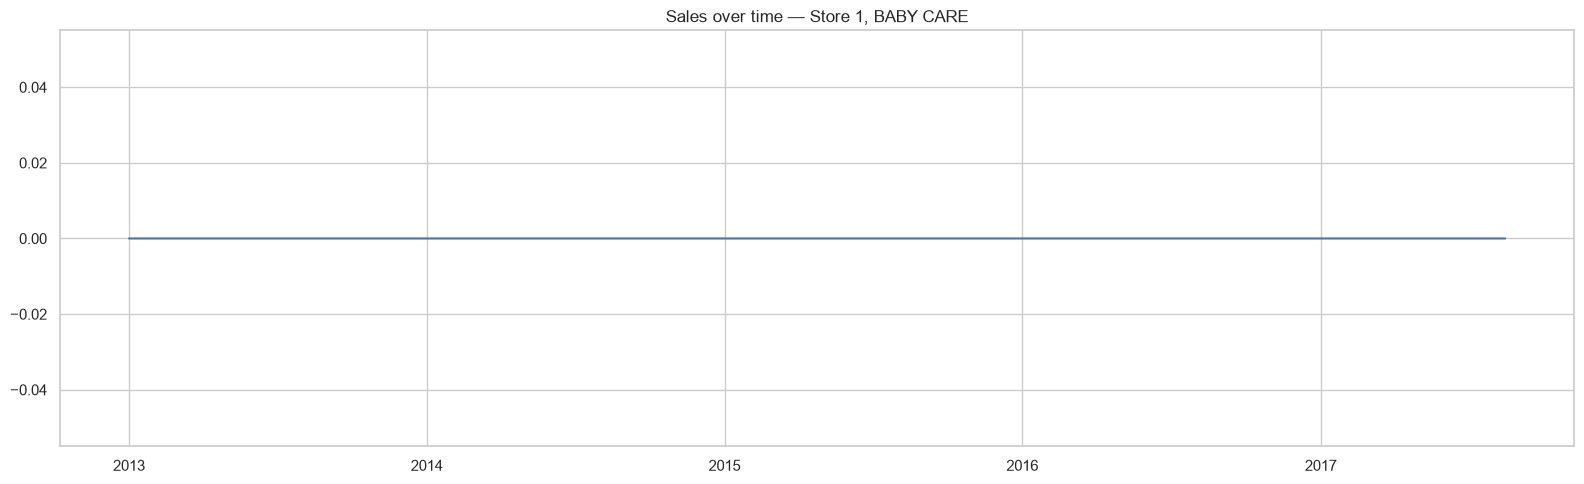

Selected series zero rate: 100.00%


In [63]:
zero_by_family=train.groupby("family").sales.agg(zero_count=lambda x:x.eq(0).sum(),zero_rate=lambda x:x.eq(0).mean()).sort_values("zero_rate",ascending=False)
zero_by_store=train.groupby("store_nbr").sales.agg(zero_count=lambda x:x.eq(0).sum(),zero_rate=lambda x:x.eq(0).mean()).sort_values("zero_rate",ascending=False)
display(zero_by_family); display(zero_by_store); display(series_summary.sort_values("zero_rate",ascending=False).head(30))
selected_series=series_summary.sort_values(["zero_rate","mean_daily_sales"],ascending=[False,True]).iloc[0]
sample_series=train.loc[train.store_nbr.eq(selected_series.store_nbr)&train.family.eq(selected_series.family)].sort_values("date")
plt.figure(figsize=(16,5)); plt.plot(sample_series.date,sample_series.sales); plt.title(f"Sales over time — Store {selected_series.store_nbr}, {selected_series.family}"); plt.tight_layout(); plt.show()
print("Selected series zero rate:",f"{selected_series.zero_rate:.2%}")


## 10. Lưu bảng tổng hợp

Khi bạn tự chạy notebook, các bảng EDA được lưu vào `reports/eda/`. Sau đó điền Key Findings dựa trên bảng và biểu đồ thực tế.


In [64]:
eda_reports={
 "shape_report.csv":shape_report,"sales_summary.csv":sales_summary,"sales_quantiles.csv":sales_quantiles,
 "daily_sales.csv":daily_sales,"weekday_summary.csv":weekday_summary,"month_summary.csv":month_summary,
 "year_month_sales.csv":year_month_sales,"monthly_by_year.csv":monthly_by_year,"normalized_year_month.csv":normalized_year_month,"family_summary.csv":family_summary,"store_summary.csv":store_summary,
 "series_summary.csv":series_summary,"promotion_summary.csv":promotion_summary,"promotion_sales_summary.csv":promo_sales_summary,
 "transaction_correlation.csv":transaction_corr,"oil_correlation.csv":oil_corr,"holiday_type_summary.csv":holiday_type_summary,
 "holiday_locale_summary.csv":holiday_locale_summary,"holiday_transferred_summary.csv":transferred_summary,
 "holiday_day_summary.csv":holiday_day_summary,"holiday_store_summary.csv":holiday_store_eda,"holiday_sales_comparison.csv":holiday_sales_comparison,"zero_by_family.csv":zero_by_family,"zero_by_store.csv":zero_by_store}
for filename,report in eda_reports.items():
 report.to_csv(EDA_DIR/filename)
 print("Saved:",filename)


Saved: shape_report.csv
Saved: sales_summary.csv
Saved: sales_quantiles.csv
Saved: daily_sales.csv
Saved: weekday_summary.csv
Saved: month_summary.csv
Saved: year_month_sales.csv
Saved: monthly_by_year.csv
Saved: normalized_year_month.csv
Saved: family_summary.csv
Saved: store_summary.csv
Saved: series_summary.csv
Saved: promotion_summary.csv
Saved: promotion_sales_summary.csv
Saved: transaction_correlation.csv
Saved: oil_correlation.csv
Saved: holiday_type_summary.csv
Saved: holiday_locale_summary.csv
Saved: holiday_transferred_summary.csv
Saved: holiday_day_summary.csv
Saved: holiday_store_summary.csv
Saved: holiday_sales_comparison.csv
Saved: zero_by_family.csv
Saved: zero_by_store.csv


## 11. Key Findings and Conclusion

### 1. Sales Distribution
- Sales có phân phối lệch phải mạnh; mean khoảng 357.78, median 11.
- Khoảng 31.30% quan sát có sales bằng 0.
- Giá trị lớn nhất 124,717; không tự động loại outlier.
- Thử `log1p(sales)` trong modeling và inverse transform trước khi tính RMSLE.

### 2. Time Trend and Seasonality
- Sales tăng đáng kể qua các năm.
- Sunday và Saturday có average daily sales cao nhất; Thursday thấp nhất.
- December có average daily sales gộp cao nhất, nhưng cần đối chiếu thêm chỉ số tháng chuẩn hóa theo trung bình từng năm trước khi kết luận seasonality.

### 3. Store and Family Analysis
- Một số Family có zero rate cao: BOOKS 96.96%, BABY CARE 94.13%, SCHOOL AND OFFICE SUPPLIES 74.08%, HOME APPLIANCES 73.52%, LADIESWEAR 59.85%.
- Store 52 có zero rate khoảng 93.54%.
- Store 54–BOOKS, Store 50–BABY CARE, Store 49–BABY CARE không có sales dương trong giai đoạn train; cần điều tra, chưa xóa.

### 4. Promotion Analysis
- Nhóm có nhiều sản phẩm khuyến mãi có mean sales cao hơn.
- Đây là liên hệ quan sát được, không phải bằng chứng promotion gây tăng sales.

### 5. Transactions Analysis
- Spearman correlation Store-Date giữa transactions và sales tổng hợp khoảng 0.8175.
- Có 83,488 Store-Date observations; 7,448 giao dịch thiếu sau left join.
- Transactions chỉ có đến 2017-08-15; không dùng giao dịch thực tế cùng ngày validation/test làm feature.

### 6. Oil Analysis
- Oil có 43 NaN tường minh; sau ghép ở cấp ngày, 521 ngày train thiếu giá: 481 ngày không có bản ghi oil và 40 ngày có bản ghi nhưng giá NaN.
- Spearman correlation tổng hợp khoảng -0.6603; xu hướng thời gian có thể ảnh hưởng, không diễn giải nhân quả.

### 7. Holiday Analysis
- Store-Date có active holiday có mean sales cao hơn nhóm ngày không thuộc category đang xét (13,974.51 so với 11,691.15).
- National và Local active holiday cũng có mean sales quan sát cao hơn nhóm ngày không thuộc category đang xét.
- Transfer date có mean sales tương đối cao trong các nhóm được so sánh.
- Regional active holiday chỉ có 31 Store-Date observations, nên cần diễn giải thận trọng.
- Đây là các so sánh mô tả; chưa kiểm soát thứ trong tuần, quy mô cửa hàng, Family hay xu hướng theo năm và không chứng minh quan hệ nhân quả.
### 8. Implications
- Giữ sales gốc và missing oil; không xóa zero-heavy series theo mặc định.
- Tổng hợp holiday theo Date-Store trước khi merge.
- Giữ transactions lịch sử riêng; dùng lag hoặc dự báo giao dịch ở giai đoạn modeling.
